# Assignment 1 — From Classification to Autoencoders
**IA Generativa · UFSC · 2026/2**  
**Aluno:** Kauan Abegg

Implementação em PyTorch das quatro partes obrigatórias. Comentários e respostas
em português. O VAE opcional não foi incluído, pois não faz parte da avaliação.

**Como executar no Google Colab:** abra este `.ipynb`, escolha uma GPU nas
configurações de ambiente de execução, se disponível, e use **Executar tudo**.
CPU também funciona, mas demora mais. As bibliotecas usadas normalmente já estão
disponíveis no Colab. O MNIST é baixado automaticamente.

**Organização:** primeiro ficam as ferramentas de treinamento; depois, as partes
1–4, com tabelas, gráficos e respostas. A definição do autoencoder convolucional é
antecipada na parte 3 para manter o mesmo orçamento dos autoencoders MLP.

**Uso de IA:** houve auxílio de IA na elaboração e revisão do código e das
explicações. As saídas salvas correspondem a treinamentos reais, com resultados medidos.

**Execução registrada:** experimentos treinados localmente em CPU com PyTorch 2.7.1; históricos, checkpoints, métricas e figuras reunidos neste notebook. As células de treinamento reproduzem os experimentos ao usar Executar tudo. Os números nas respostas escritas descrevem a execução salva; se refizer o treinamento em outro ambiente, revise essas respostas com os novos valores.


## Configuração e separação dos dados
As imagens são tensores `(N, 1, 28, 28)` com pixels entre 0 e 1. Os 60.000
exemplos de desenvolvimento são separados em **50.000 de treino** e **10.000 de
validação**. Os **10.000 exemplos do teste oficial** ficam reservados à avaliação
final. A validação escolhe o checkpoint; o teste não decide arquitetura nem épocas.

A semente controla a inicialização e a divisão. Cada modelo possui seu próprio
gerador do embaralhamento, iniciado com a mesma semente: o sorteio do Dropout não
altera a ordem dos exemplos. Resultados podem variar entre versões, CPU e GPU.

In [1]:
# Bibliotecas usadas no trabalho.
import copy  # Guarda uma cópia dos melhores pesos.
import random  # Controla a aleatoriedade do Python.
import time  # Mede o tempo de treinamento.
import numpy as np  # Auxilia nos cálculos e nos gráficos.
import pandas as pd  # Organiza os resultados em tabelas.
import matplotlib.pyplot as plt  # Desenha as curvas e as imagens.
import torch  # Biblioteca de aprendizado profundo.
from torch import nn  # Camadas, funções de perda e modelos.
import torch.nn.functional as F  # ReLU e pooling.
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
from IPython.display import display, Markdown

SEED = 42  # Mesma semente em todos os experimentos.
BATCH_SIZE = 128  # Número de imagens por atualização.
LR = 0.001  # Taxa de aprendizado do Adam.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)  # Evita excesso de threads na execução em CPU.

def set_seed():
    """Repete as sementes antes de construir cada modelo."""
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    # Reduz variações entre execuções na mesma GPU.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("PyTorch:", torch.__version__, "| Dispositivo:", device)
print("Semente:", SEED, "| Batch:", BATCH_SIZE, "| Adam lr:", LR)

# A mesma escala [0, 1] serve para classificação e reconstrução.
transform = transforms.ToTensor()
full_train = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_data = datasets.MNIST("./data", train=False, download=True, transform=transform)

# Converte uma vez, em vez de converter cada imagem novamente em cada época.
# A operação é exatamente a escala do ToTensor para imagens uint8 do MNIST.
full_train = TensorDataset(full_train.data.unsqueeze(1).float() / 255, full_train.targets)
test_data = TensorDataset(test_data.data.unsqueeze(1).float() / 255, test_data.targets)

# O teste oficial fica separado: 50 mil treino, 10 mil validação, 10 mil teste.
train_data, val_data = random_split(
    full_train, [50_000, 10_000],
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

def make_train_loader():
    """Cada modelo recebe a mesma sequência de lotes, independente do Dropout."""
    return DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )

# Confere que nenhuma imagem pertence simultaneamente a treino e validação.
assert set(train_data.indices).isdisjoint(val_data.indices)
print("Imagens:", len(train_data), "treino /", len(val_data), "validação /",
      len(test_data), "teste")

PyTorch: 2.7.1+cpu | Dispositivo: cpu
Semente: 42 | Batch: 128 | Adam lr: 0.001
Imagens: 50000 treino / 10000 validação / 10000 teste


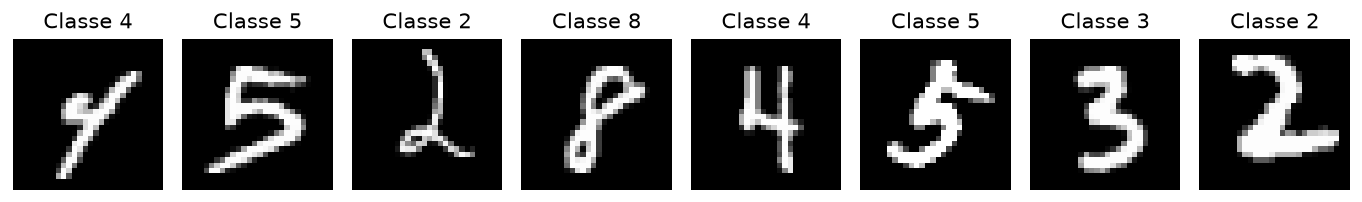

In [2]:
# Mostra oito exemplos da validação sem consultar o teste.
images, labels = next(iter(val_loader))
fig, axes = plt.subplots(1, 8, figsize=(11, 2))
for i, ax in enumerate(axes):
    ax.imshow(images[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Funções de treinamento e critério de parada
Uma **época** percorre todo o conjunto de treino. Cada lote segue:
`zero_grad → forward → loss → backward → step`. Na validação não há atualização.

O teste inicial dura **5 épocas**. Em seguida, os mesmos modelos continuam até
**15 épocas totais para cada classificador** e **30 para cada autoencoder**.
Esses são orçamentos comuns de execução, não uma garantia de convergência.
As curvas e a tabela de ganho nas últimas cinco épocas permitem verificar se há
estabilização ou se mais treinamento ainda seria útil. O orçamento limitado
também é uma limitação do experimento e deve ser considerado na comparação.

Ao terminar, recuperamos os pesos da **menor perda de validação de toda a execução**.
A época desse checkpoint pode ser diferente da última época treinada.
Não restauramos o melhor checkpoint entre as etapas de treinamento: assim,
a continuação mantém os pesos atuais e os momentos internos do Adam.

A perda é ponderada pelo número de imagens de cada lote. Para imagens de tamanho
fixo, `nn.MSELoss()` seguido dessa média produz o **MSE médio por pixel**.

In [3]:
def run_epoch(model, loader, criterion, optimizer=None, classification=True):
    """Treina se receber optimizer; caso contrário, somente avalia."""
    training = optimizer is not None
    model.train(training)  # True: treinamento; False: mesmo efeito de model.eval().
    total_loss, total_correct, total_seen = 0.0, 0, 0
    with torch.set_grad_enabled(training):  # Sem grafo de gradientes na avaliação.
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            if training:
                optimizer.zero_grad()  # Não acumula gradientes de lotes anteriores.
            outputs = model(images)  # Calcula as previsões ou reconstruções.
            targets = labels if classification else images  # AE tenta reproduzir x.
            loss = criterion(outputs, targets)
            if training:
                loss.backward()  # Calcula os gradientes.
                optimizer.step()  # Atualiza os pesos usando Adam.
            count = images.shape[0]
            total_loss += loss.item() * count  # Pondera pelo tamanho real do lote.
            total_seen += count
            if classification:
                total_correct += (outputs.argmax(dim=1) == labels).sum().item()
    stats = {"loss": total_loss / total_seen}  # MSE médio por pixel para o AE.
    if classification:
        stats["accuracy"] = total_correct / total_seen
    return stats

def new_experiment(model, classification=True):
    """Agrupa tudo que deve ser preservado ao continuar o treinamento."""
    model = model.to(device)
    return {
        "model": model,
        "optimizer": torch.optim.Adam(model.parameters(), lr=LR),
        "criterion": nn.CrossEntropyLoss() if classification else nn.MSELoss(),
        "classification": classification,
        "loader": make_train_loader(),
        "history": {"train_loss": [], "val_loss": [],
                    "train_accuracy": [], "val_accuracy": []},
        "best_loss": float("inf"), "best_epoch": 0, "best_weights": None,
        "seconds": 0.0,
    }

def train_more(experiment, epochs, name="Modelo"):
    """Acrescenta épocas sem reiniciar pesos, Adam, lotes ou histórico."""
    start = time.perf_counter()
    for _ in range(epochs):
        tr = run_epoch(experiment["model"], experiment["loader"],
                       experiment["criterion"], experiment["optimizer"],
                       experiment["classification"])
        va = run_epoch(experiment["model"], val_loader, experiment["criterion"],
                       classification=experiment["classification"])
        history = experiment["history"]
        for split, stats in [("train", tr), ("val", va)]:
            history[split + "_loss"].append(stats["loss"])
            if experiment["classification"]:
                history[split + "_accuracy"].append(stats["accuracy"])
        epoch = len(history["val_loss"])
        if va["loss"] < experiment["best_loss"]:
            experiment["best_loss"] = va["loss"]  # Seleção usa apenas validação.
            experiment["best_epoch"] = epoch
            experiment["best_weights"] = copy.deepcopy(experiment["model"].state_dict())
        print(f'{name} | época {epoch:02d} | treino {tr["loss"]:.6f} | '
              f'validação {va["loss"]:.6f}', flush=True)
    experiment["seconds"] += time.perf_counter() - start

def restore_best(experiment):
    """Restaura o checkpoint apenas depois de encerrar o treinamento."""
    experiment["model"].load_state_dict(experiment["best_weights"])
    experiment["model"].eval()
    return experiment["model"]

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [4]:
def plot_history(experiment, title):
    """Mostra treino e validação; a linha vertical indica o checkpoint escolhido."""
    history = experiment["history"]
    classification = experiment["classification"]
    fig, axes = plt.subplots(1, 2 if classification else 1,
                             figsize=(11 if classification else 6, 3.3))
    axes = np.atleast_1d(axes)
    epochs = np.arange(1, len(history["val_loss"]) + 1)
    axes[0].plot(epochs, history["train_loss"], label="Treino")
    axes[0].plot(epochs, history["val_loss"], label="Validação")
    axes[0].set_ylabel("Entropia cruzada" if classification else "MSE por pixel")
    if classification:
        axes[1].plot(epochs, history["train_accuracy"], label="Treino")
        axes[1].plot(epochs, history["val_accuracy"], label="Validação")
        axes[1].set_ylabel("Acurácia")
    for ax in axes:
        ax.axvline(experiment["best_epoch"], color="gray", linestyle=":",
                   label="Melhor época de validação")
        ax.set_xlabel("Época")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def convergence_row(name, experiment):
    """Quantifica quanto o melhor valor melhorou nas últimas cinco épocas."""
    losses = experiment["history"]["val_loss"]
    previous = min(losses[:-5]) if len(losses) > 5 else losses[0]
    gain = 100 * (previous - min(losses)) / previous
    return {"Modelo": name, "Épocas": len(losses),
            "Melhor época": experiment["best_epoch"],
            "Melhor validação": min(losses),
            "Ganho absoluto últimas 5": previous - min(losses),
            "Ganho últimas 5 (%)": gain}

## Parte 1 — Classificação com CNN
Arquitetura da aula: duas sequências `Conv → ReLU → MaxPool`, seguidas de
duas camadas totalmente conectadas. Com BatchNorm, a normalização fica entre
convolução e ReLU. Com Dropout, ele fica depois da ativação da camada escondida.

Formato: `1×28×28 → 32×14×14 → 64×7×7 → 3136 → 128 → 10`.

In [5]:
class SimpleCNN(nn.Module):
    """Arquitetura da aula, com opções independentes de Dropout e BatchNorm."""
    def __init__(self, use_dropout=False, use_batchnorm=False):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)  # 28 x 28 permanece 28 x 28.
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)  # Mantém a resolução de entrada.
        self.bn1 = nn.BatchNorm2d(32) if use_batchnorm else nn.Identity()
        self.bn2 = nn.BatchNorm2d(64) if use_batchnorm else nn.Identity()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)  # Dois poolings: 28 -> 14 -> 7.
        self.fc2 = nn.Linear(128, 10)  # Um logit para cada dígito.
        self.dropout = nn.Dropout(0.5) if use_dropout else nn.Identity()

    def forward(self, x):
        x = self.conv1(x)  # Extrai padrões locais.
        x = F.relu(self.bn1(x))  # BatchNorm, quando presente, vem antes da ReLU.
        x = F.max_pool2d(x, 2)  # (N, 32, 14, 14).
        x = self.conv2(x)  # Combina os padrões anteriores.
        x = F.relu(self.bn2(x))
        x = F.max_pool2d(x, 2)  # (N, 64, 7, 7).
        x = torch.flatten(x, start_dim=1)  # Preserva a dimensão do lote N.
        x = F.relu(self.fc1(x))  # Camada escondida.
        x = self.dropout(x)  # Dropout somente aqui, nunca nos logits finais.
        return self.fc2(x)  # CrossEntropyLoss recebe logits, sem Softmax.

In [6]:
# Testa tamanho da saída e preservação do lote nas três configurações.
for drop, bn in [(False, False), (True, False), (False, True)]:
    test_model = SimpleCNN(use_dropout=drop, use_batchnorm=bn)
    assert test_model(torch.rand(4, 1, 28, 28)).shape == (4, 10)
print("CNN: os três testes de formato passaram.")

CNN: os três testes de formato passaram.


Baseline | época 01 | treino 0.291602 | validação 0.106668
Baseline | época 02 | treino 0.066381 | validação 0.065013
Baseline | época 03 | treino 0.044396 | validação 0.053465
Baseline | época 04 | treino 0.033197 | validação 0.043685
Baseline | época 05 | treino 0.026581 | validação 0.040432


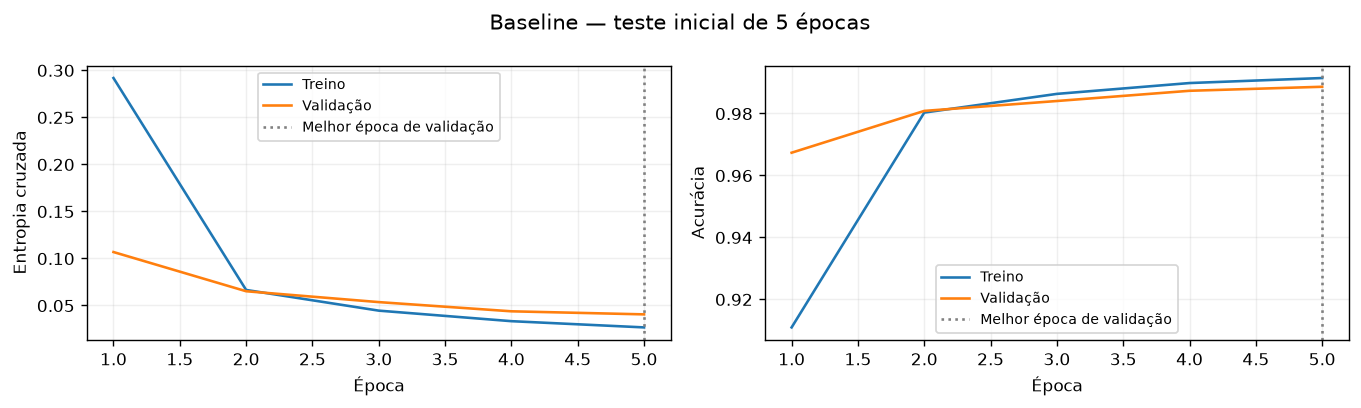

In [7]:
# Primeiro, verifica que a CNN aprende durante cinco épocas.
set_seed()
baseline_exp = new_experiment(SimpleCNN(), classification=True)
train_more(baseline_exp, 5, "Baseline")
plot_history(baseline_exp, "Baseline — teste inicial de 5 épocas")

Baseline | época 06 | treino 0.020220 | validação 0.043951
Baseline | época 07 | treino 0.016511 | validação 0.037794
Baseline | época 08 | treino 0.013791 | validação 0.041530
Baseline | época 09 | treino 0.010813 | validação 0.045685
Baseline | época 10 | treino 0.010429 | validação 0.039576
Baseline | época 11 | treino 0.007752 | validação 0.042543
Baseline | época 12 | treino 0.008424 | validação 0.048713
Baseline | época 13 | treino 0.006705 | validação 0.052549
Baseline | época 14 | treino 0.004092 | validação 0.053760
Baseline | época 15 | treino 0.005577 | validação 0.049102


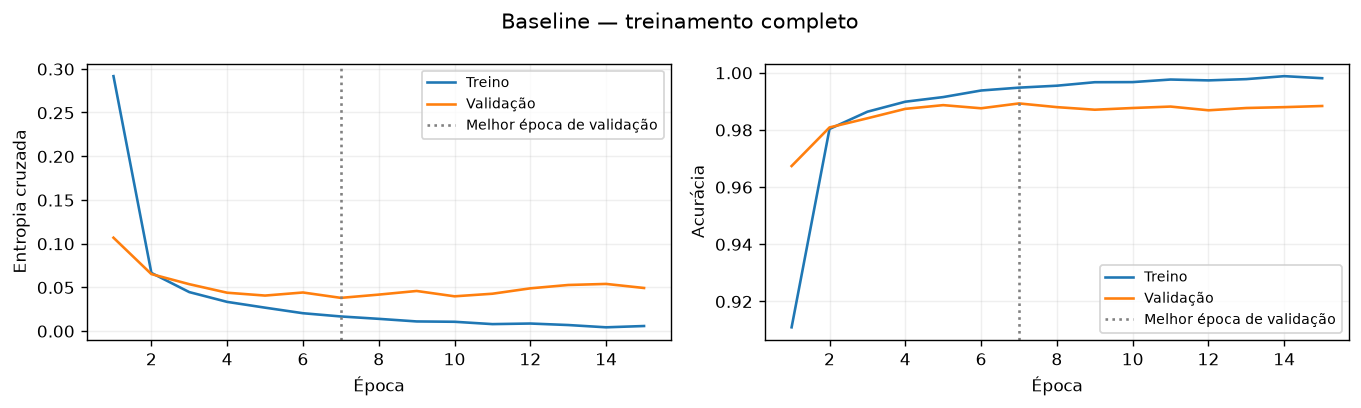

In [8]:
# Continua o MESMO treinamento: 5 iniciais + 10 adicionais = 15 épocas.
CNN_EPOCHS = 15
train_more(baseline_exp, CNN_EPOCHS - 5, "Baseline")
baseline = restore_best(baseline_exp)  # Somente agora recupera os melhores pesos.
plot_history(baseline_exp, "Baseline — treinamento completo")

In [9]:
# Uma única avaliação final no teste para a CNN baseline.
baseline_test = run_epoch(baseline, test_loader, nn.CrossEntropyLoss(),
                          classification=True)
h = baseline_exp["history"]
best = baseline_exp["best_epoch"] - 1  # Listas começam no índice zero.
baseline_table = pd.DataFrame([{
    "Épocas executadas": len(h["val_loss"]),
    "Melhor época": best + 1,
    "Acurácia treino última época": h["train_accuracy"][-1],
    "Acurácia validação última época": h["val_accuracy"][-1],
    "Acurácia validação checkpoint": h["val_accuracy"][best],
    "Acurácia teste checkpoint": baseline_test["accuracy"],
}])
display(baseline_table.round(6))
display(pd.DataFrame([convergence_row("Baseline", baseline_exp)]).round(6))
display(Markdown(
    f'**Resultado:** a CNN treinou por {len(h["val_loss"])} épocas. '
    f'A acurácia de treino na última época foi {h["train_accuracy"][-1]:.2%}, '
    f'a de validação {h["val_accuracy"][-1]:.2%} e a de teste do checkpoint '
    f'selecionado foi {baseline_test["accuracy"]:.2%}. '
    f'O menor erro de validação ocorreu na época {best + 1}.'
))

Épocas executadas,Melhor época,Acurácia treino última época,Acurácia validação última época,Acurácia validação checkpoint,Acurácia teste checkpoint
15,7,0.99802,0.9883,0.9892,0.9901


Modelo,Épocas,Melhor época,Melhor validação,Ganho absoluto últimas 5,Ganho últimas 5 (%)
Baseline,15,7,0.037794,0.0,0.0


**Resultado:** a CNN treinou por 15 épocas. A acurácia de treino na última época foi 99.80%, a de validação 98.83% e a de teste do checkpoint selecionado foi 99.01%. O menor erro de validação ocorreu na época 7.

### Respostas da parte 1
**1. Por que logits?** A última camada retorna dez escores sem normalização.
`CrossEntropyLoss` já combina o cálculo de `log_softmax` com a perda de
classificação de forma numericamente estável. Aplicar Softmax antes mudaria a
entrada esperada da função. Para escolher a classe, basta o maior logit (`argmax`).

**2. Acurácias e curvas.** Os valores efetivamente medidos estão na tabela e na
resposta acima. Acurácia de treino é medida durante as atualizações da época;
validação é medida ao final, com pesos fixos. A linha pontilhada marca o checkpoint
escolhido por perda, não pela maior acurácia. Uma queda contínua da perda de treino
sem melhora correspondente na validação sugere sobreajuste. A interpretação
específica desta execução é registrada após a comparação seguinte.

## Parte 2 — Dropout e BatchNorm
Comparamos três configurações separadas: baseline, Dropout `p=0.5` e BatchNorm.
O baseline é reutilizado da parte 1. Todos usam Adam, `lr=0.001`, lote 128,
semente 42, mesma divisão, mesma ordem de lotes e **15 épocas**.

Dropout | época 01 | treino 0.398394 | validação 0.103156
Dropout | época 02 | treino 0.115291 | validação 0.063192
Dropout | época 03 | treino 0.086105 | validação 0.054378
Dropout | época 04 | treino 0.069723 | validação 0.047028
Dropout | época 05 | treino 0.059400 | validação 0.044860
Dropout | época 06 | treino 0.052128 | validação 0.044722
Dropout | época 07 | treino 0.046558 | validação 0.042523
Dropout | época 08 | treino 0.043758 | validação 0.042216
Dropout | época 09 | treino 0.036377 | validação 0.042418
Dropout | época 10 | treino 0.034278 | validação 0.041340
Dropout | época 11 | treino 0.031902 | validação 0.038754
Dropout | época 12 | treino 0.029681 | validação 0.042610
Dropout | época 13 | treino 0.027485 | validação 0.039865
Dropout | época 14 | treino 0.025317 | validação 0.040891
Dropout | época 15 | treino 0.023007 | validação 0.040067
BatchNorm | época 01 | treino 0.149429 | validação 0.066470
BatchNorm | época 02 | treino 0.048062 | validação 0.058224
BatchNorm 

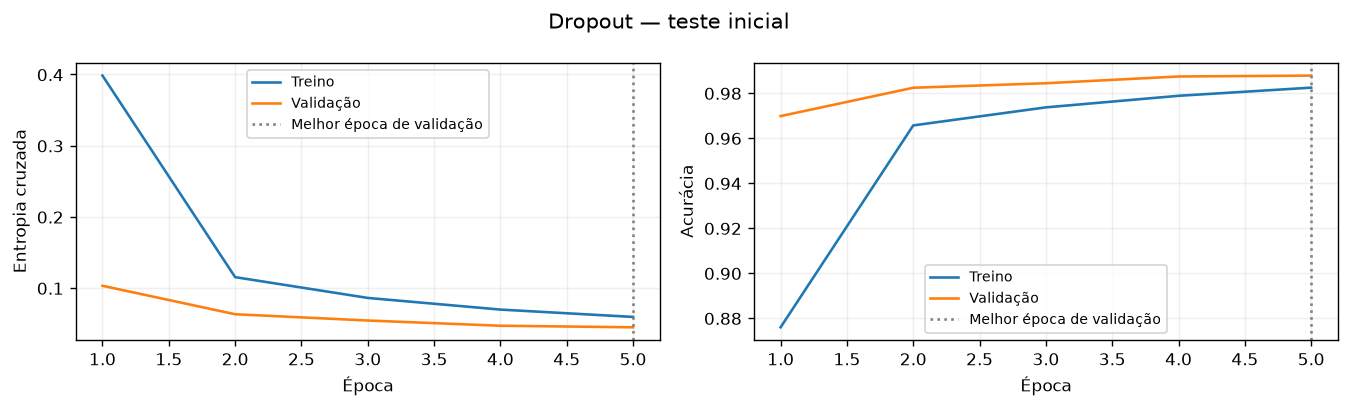

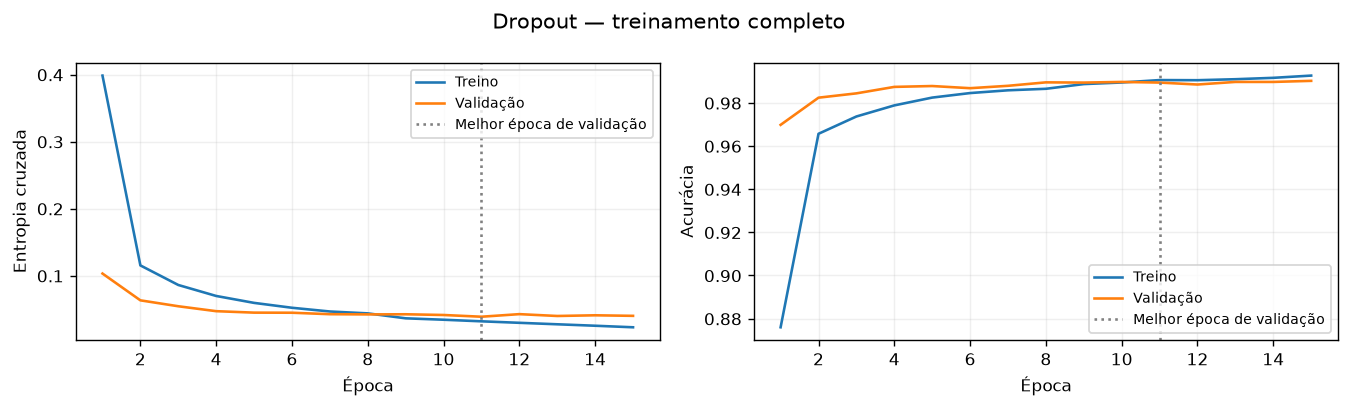

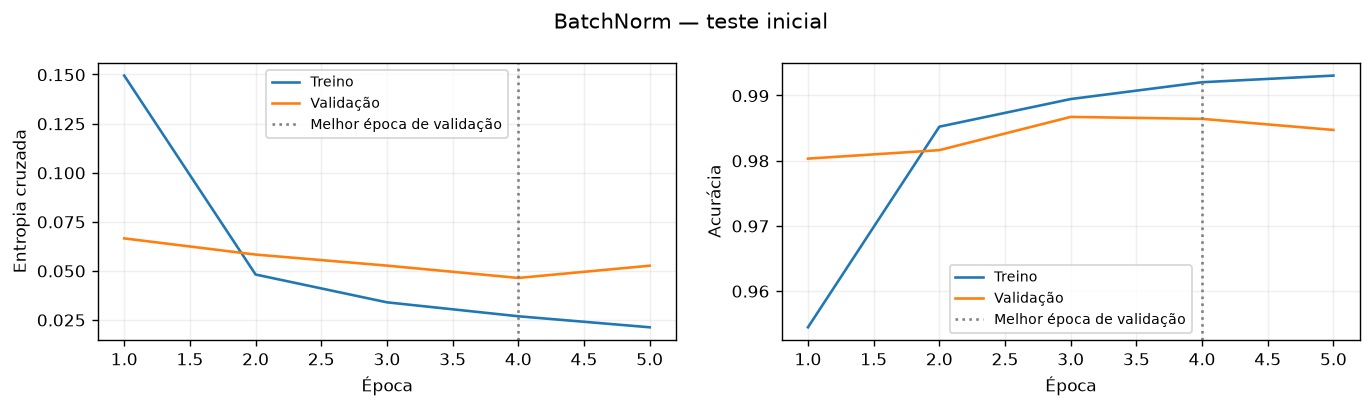

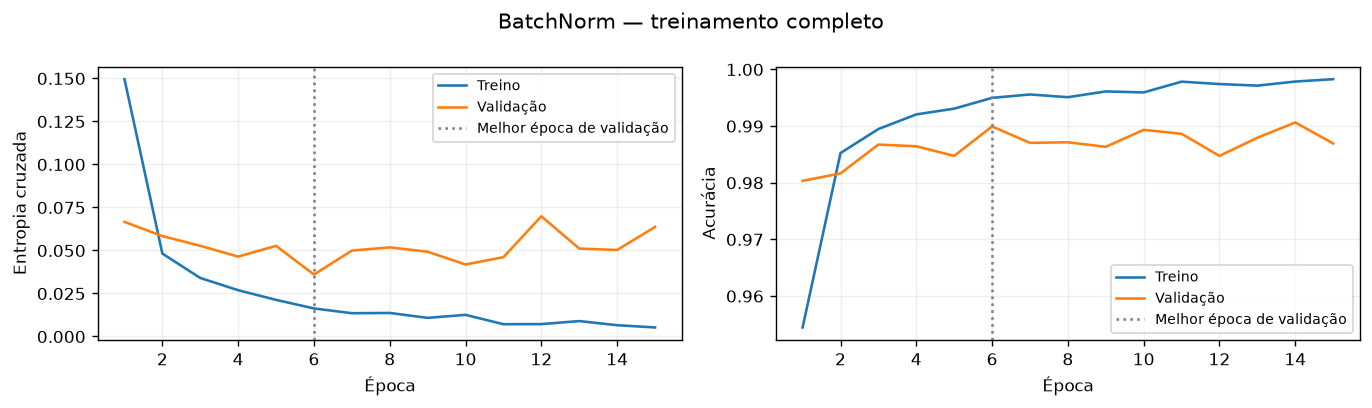

In [10]:
# Reutiliza o baseline já treinado; não o treina novamente.
experiments = {"Baseline": baseline_exp}
configs = {"Dropout": (True, False), "BatchNorm": (False, True)}
for name, (drop, bn) in configs.items():
    set_seed()  # Reinicia a semente antes de inicializar cada rede.
    exp = new_experiment(SimpleCNN(drop, bn), classification=True)
    train_more(exp, 5, name)  # Teste inicial.
    plot_history(exp, name + " — teste inicial")
    train_more(exp, CNN_EPOCHS - 5, name)  # Continua até o orçamento comum.
    restore_best(exp)
    experiments[name] = exp
    plot_history(exp, name + " — treinamento completo")

Configuração,Épocas,Acurácia treino última,Acurácia validação última,Menor perda validação,Época selecionada
Baseline,15,0.99802,0.9883,0.037794,7
Dropout,15,0.99264,0.9902,0.038754,11
BatchNorm,15,0.99824,0.9869,0.035893,6


Modelo,Épocas,Melhor época,Melhor validação,Ganho absoluto últimas 5,Ganho últimas 5 (%)
Baseline,15,7,0.037794,0.000000,0.000000
Dropout,15,11,0.038754,0.002586,6.255718
BatchNorm,15,6,0.035893,0.000000,0.000000


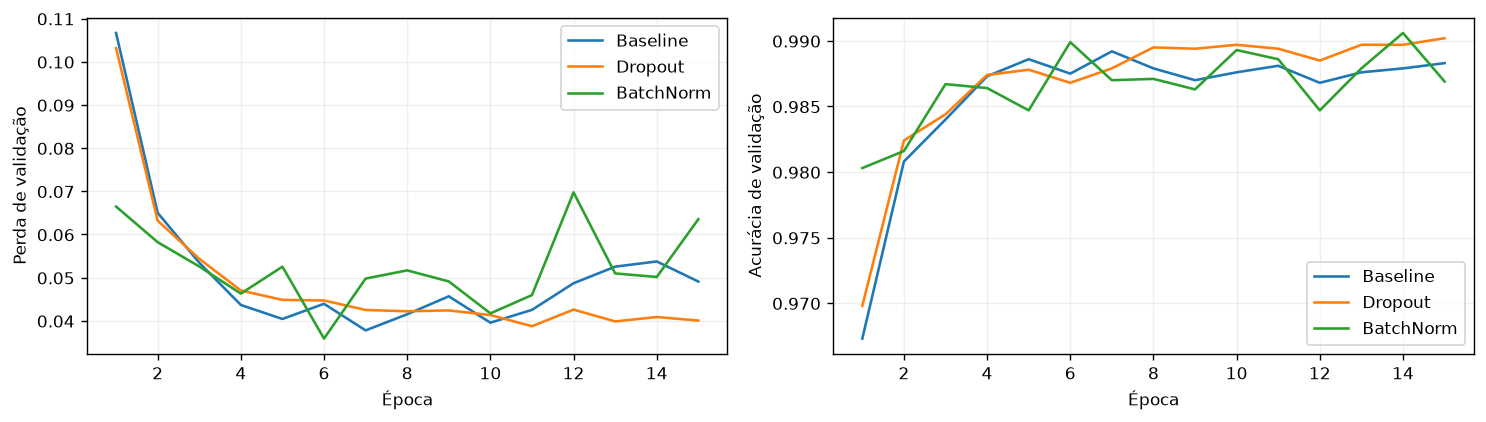

In [11]:
# Acurácias da ÚLTIMA época; a menor perda pode pertencer a outra época.
rows = []
for name, exp in experiments.items():
    h = exp["history"]
    rows.append({
        "Configuração": name, "Épocas": len(h["val_loss"]),
        "Acurácia treino última": h["train_accuracy"][-1],
        "Acurácia validação última": h["val_accuracy"][-1],
        "Menor perda validação": exp["best_loss"],
        "Época selecionada": exp["best_epoch"],
    })
cnn_table = pd.DataFrame(rows)
display(cnn_table.round(6))
display(pd.DataFrame([convergence_row(n, e) for n, e in experiments.items()]).round(6))

# Compara as curvas usando os mesmos eixos.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name, exp in experiments.items():
    h = exp["history"]
    epochs = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(epochs, h["val_loss"], label=name)
    axes[1].plot(epochs, h["val_accuracy"], label=name)
axes[0].set_ylabel("Perda de validação")
axes[1].set_ylabel("Acurácia de validação")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Respostas da parte 2
**Dropout:** durante o treino, zera aleatoriamente metade das ativações da camada
escondida. Isso dificulta a dependência de poucos neurônios e pode reduzir o
sobreajuste. No PyTorch, as ativações mantidas são escaladas durante o treino;
na avaliação, o Dropout age como identidade. A acurácia de treino com Dropout é
medida com essa perturbação ativa e não é diretamente equivalente à avaliação.

**BatchNorm:** normaliza as ativações usando estatísticas do lote no treinamento
e aprende escala e deslocamento. Na avaliação, usa as médias e variâncias
acumuladas. Pode modificar a velocidade e a estabilidade do aprendizado; isso
não garante melhor acurácia em toda execução.

**Por que `model.eval()`?** Ele desativa o sorteio do Dropout e faz BatchNorm usar
as estatísticas acumuladas. Sem isso, as previsões e a medição podem depender do
lote e da aleatoriedade do treinamento.

**Qual a diferença para `torch.no_grad()`?** `no_grad` evita construir o grafo
de derivadas, reduzindo memória e trabalho. Ele não altera Dropout nem BatchNorm.
`eval()` altera o comportamento dessas camadas, mas não desliga os gradientes.
Por isso usamos ambos. Em `run_epoch`, `model.train(False)` e
`torch.set_grad_enabled(False)` cumprem esses dois papéis.

### Observações desta execução
O baseline teve a menor perda de validação na época **7**,
entre as 15 executadas. Na época 5 sua perda de validação era
**0.040432**; o melhor valor final foi
**0.037794**. Assim, encerrar automaticamente no teste inicial
teria ignorado as épocas seguintes.

- **Baseline:** última acurácia de treino 99.80%, validação 98.83%; menor perda de validação 0.037794, na época 7.
- **Dropout:** última acurácia de treino 99.26%, validação 99.02%; menor perda de validação 0.038754, na época 11.
- **BatchNorm:** última acurácia de treino 99.82%, validação 98.69%; menor perda de validação 0.035893, na época 6.


Comparamos o comportamento completo, não apenas a acurácia: a entropia cruzada
também penaliza a confiança atribuída às previsões erradas. Por isso ela pode
piorar enquanto a acurácia muda pouco. O melhor checkpoint limita o efeito do
sobreajuste, mas não elimina a incerteza de avaliar somente uma semente.
O limite de 15 épocas encerra o experimento; não prova convergência de todas as
configurações. A tabela de ganho nas últimas cinco épocas mostra essa diferença.

## Parte 3 — Autoencoder MLP e espaço latente
O encoder comprime a imagem e o decoder tenta reconstruí-la.
O alvo agora é **a própria imagem**, e os rótulos não participam do treinamento.
Implementamos `784 → 128 → d → 128 → 784`, com `d = 2, 16, 64`.

In [12]:
class MLPAutoencoder(nn.Module):
    """Autoencoder com camadas totalmente conectadas."""
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 128),  # Cada imagem contém 28 x 28 = 784 pixels.
            nn.ReLU(),  # Acrescenta não linearidade.
            nn.Linear(128, latent_dim)  # Gargalo: 2, 16 ou 64 valores.
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),  # Expande o código latente.
            nn.ReLU(),
            nn.Linear(128, 784),  # Produz todos os pixels.
            nn.Sigmoid(),  # Restringe os pixels reconstruídos a [0, 1].
        )

    def encode(self, x):
        return self.encoder(torch.flatten(x, start_dim=1))  # (N, 784) -> (N, d).

    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)  # Recupera o formato da imagem.

    def forward(self, x):
        return self.decode(self.encode(x))  # Comprime e reconstrói.

### Arquitetura convolucional da parte 4, definida antecipadamente
Para usar um único orçamento na comparação, definimos também o autoencoder CNN
antes dos treinamentos. A arquitetura abaixo segue exatamente a sugestão do
enunciado. A análise e a avaliação no teste estão na parte 4.

In [13]:
class ConvAutoencoder(nn.Module):
    """Arquitetura convolucional sugerida no enunciado, sem pesos pré-treinados."""
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1),  # 28 -> 14.
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1),  # 14 -> 7.
            nn.ReLU(),
        )
        self.encoder_fc = nn.Linear(32 * 7 * 7, latent_dim)  # Gargalo vetorial.
        self.decoder_fc = nn.Linear(latent_dim, 32 * 7 * 7)  # Expande o gargalo.
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1),  # 7 -> 14.
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 4, stride=2, padding=1),  # 14 -> 28.
            nn.Sigmoid(),  # Mesmo intervalo dos pixels de entrada.
        )

    def encode(self, x):
        features = self.encoder_conv(x)  # Obtém mapas espaciais 7 x 7.
        return self.encoder_fc(torch.flatten(features, start_dim=1))

    def decode(self, z):
        features = F.relu(self.decoder_fc(z))  # Projeta o vetor latente.
        features = features.reshape(-1, 32, 7, 7)  # Reorganiza em mapas espaciais.
        return self.decoder_conv(features)  # Aprende a aumentar a resolução.

    def forward(self, x):
        return self.decode(self.encode(x))

In [14]:
# Confere o gargalo, a reconstrução, os limites de pixels e os gradientes.
for cls, dims in [(MLPAutoencoder, [2, 16, 64]), (ConvAutoencoder, [16, 64])]:
    for dim in dims:
        model = cls(dim)
        x = torch.rand(4, 1, 28, 28)
        assert model.encode(x).shape == (4, dim)
        recon = model(x)
        assert recon.shape == x.shape
        assert torch.all((recon >= 0) & (recon <= 1))
        nn.MSELoss()(recon, x).backward()  # Confere que o decoder está ligado ao encoder.
        assert all(p.grad is not None and torch.isfinite(p.grad).all()
                   for p in model.parameters())
print("MLP e CNN: formatos, intervalo e gradientes verificados.")

MLP e CNN: formatos, intervalo e gradientes verificados.


### 3.2 Treinamento e convergência
Todos os cinco autoencoders recebem **30 épocas**, com cinco iniciais de teste
e vinte e cinco de continuação. Após inspecionar a melhora que ainda ocorria até
a época 20, estendemos o orçamento comum até 30. As curvas de treino e validação são mostradas para cada
modelo. O melhor checkpoint é escolhido independentemente por validação.
O MLP com duas dimensões também participa desse orçamento comum.

MLP_2 | época 01 | treino 0.065199 | validação 0.054044
MLP_2 | época 02 | treino 0.052457 | validação 0.050942
MLP_2 | época 03 | treino 0.050243 | validação 0.049255
MLP_2 | época 04 | treino 0.048949 | validação 0.048283
MLP_2 | época 05 | treino 0.048063 | validação 0.047519
MLP_2 | época 06 | treino 0.047343 | validação 0.046913
MLP_2 | época 07 | treino 0.046790 | validação 0.046497
MLP_2 | época 08 | treino 0.046352 | validação 0.046138
MLP_2 | época 09 | treino 0.045973 | validação 0.045804
MLP_2 | época 10 | treino 0.045637 | validação 0.045543
MLP_2 | época 11 | treino 0.045335 | validação 0.045255
MLP_2 | época 12 | treino 0.045070 | validação 0.045102
MLP_2 | época 13 | treino 0.044816 | validação 0.044852
MLP_2 | época 14 | treino 0.044575 | validação 0.044660
MLP_2 | época 15 | treino 0.044359 | validação 0.044535
MLP_2 | época 16 | treino 0.044140 | validação 0.044361
MLP_2 | época 17 | treino 0.043955 | validação 0.044219
MLP_2 | época 18 | treino 0.043755 | validação 0

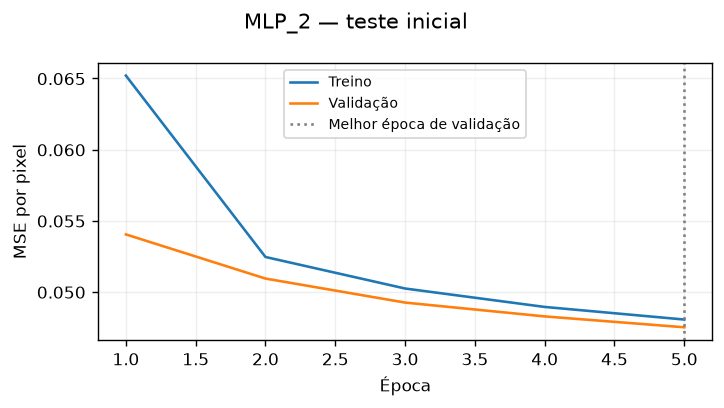

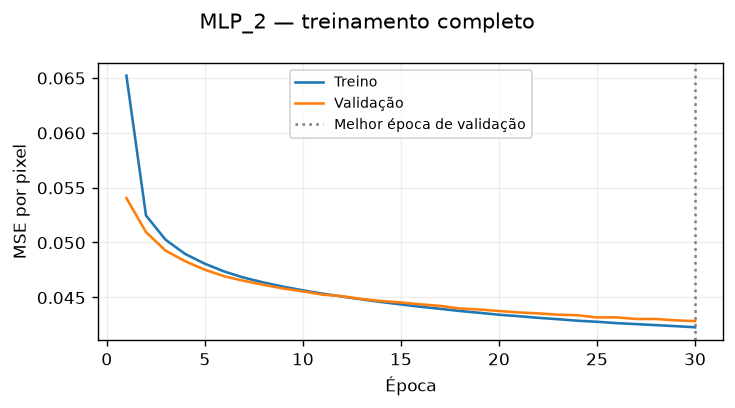

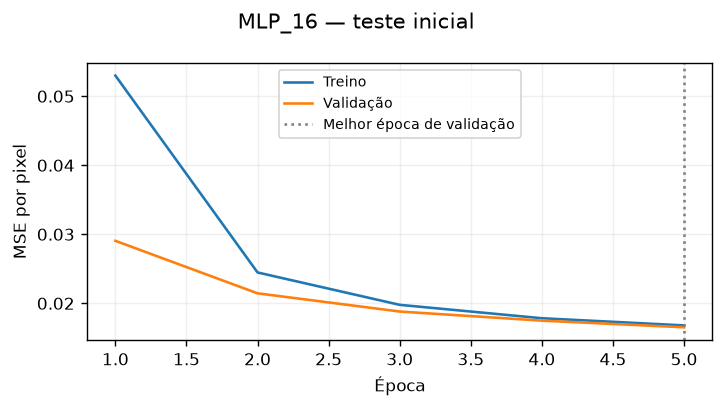

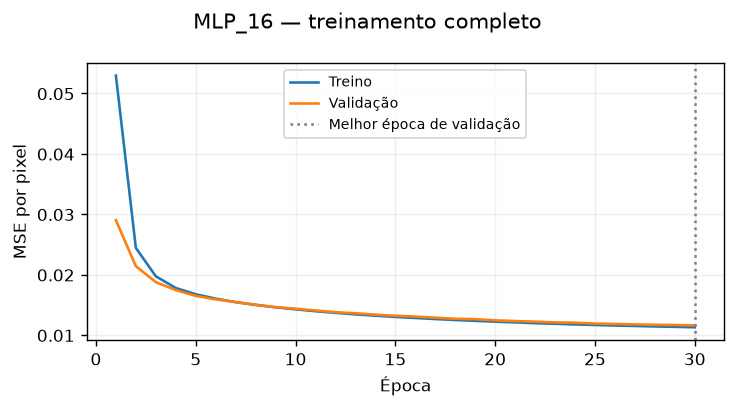

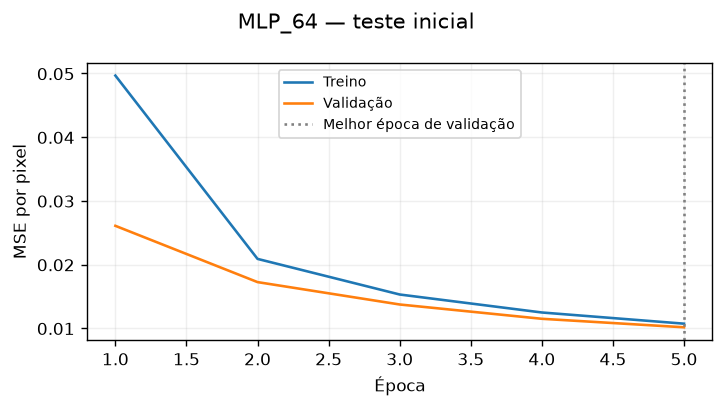

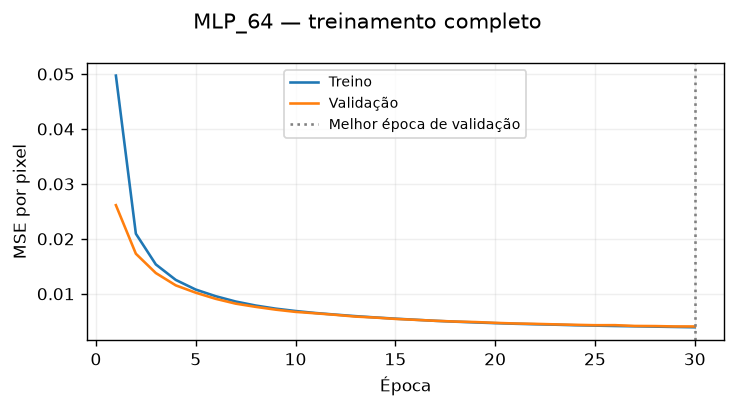

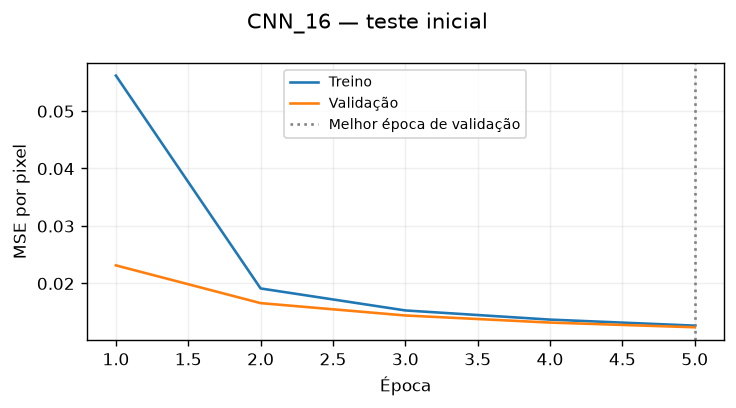

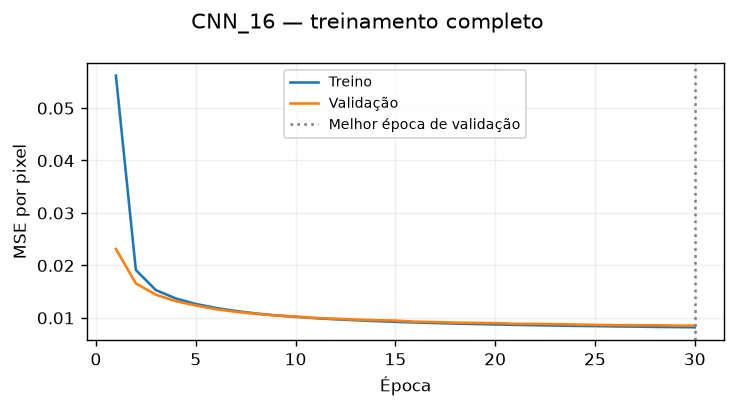

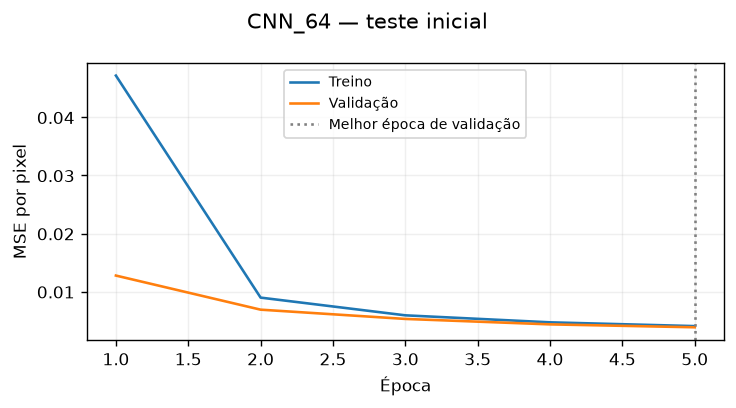

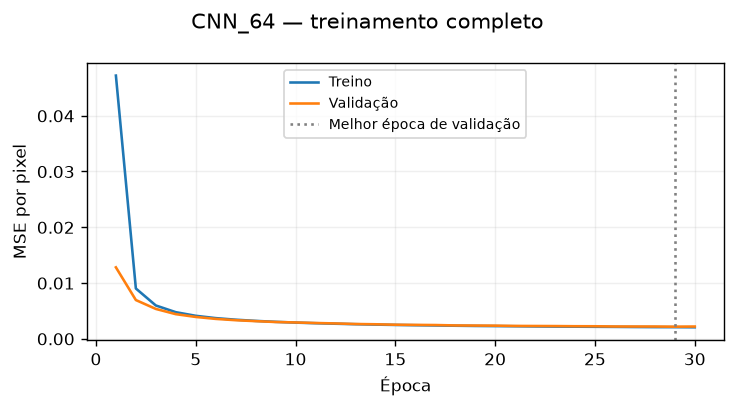

Modelo,Épocas,Melhor época,Melhor validação,Ganho absoluto últimas 5,Ganho últimas 5 (%)
MLP_2,30,30,0.042836,0.000334,0.773810
MLP_16,30,30,0.011613,0.000297,2.489802
MLP_64,30,30,0.004007,0.000229,5.405815
CNN_16,30,30,0.008472,0.000151,1.755980
CNN_64,30,29,0.002138,0.000074,3.347305


In [15]:
AE_EPOCHS = 30  # Orçamento comum, estendido após verificar a validação até a época 20.
ae_experiments = {}
ae_configs = [
    ("MLP_2", MLPAutoencoder, 2),
    ("MLP_16", MLPAutoencoder, 16),
    ("MLP_64", MLPAutoencoder, 64),
    ("CNN_16", ConvAutoencoder, 16),
    ("CNN_64", ConvAutoencoder, 64),
]
for name, cls, dim in ae_configs:
    set_seed()
    exp = new_experiment(cls(dim), classification=False)
    train_more(exp, 5, name)
    plot_history(exp, name + " — teste inicial")
    train_more(exp, AE_EPOCHS - 5, name)
    restore_best(exp)
    ae_experiments[name] = exp
    plot_history(exp, name + " — treinamento completo")

# Mantém nomes simples para acessar os modelos nas visualizações.
autoencoders = {d: ae_experiments[f"MLP_{d}"]["model"] for d in [2, 16, 64]}
conv_autoencoders = {d: ae_experiments[f"CNN_{d}"]["model"] for d in [16, 64]}
display(pd.DataFrame([convergence_row(n, e) for n, e in ae_experiments.items()]).round(6))

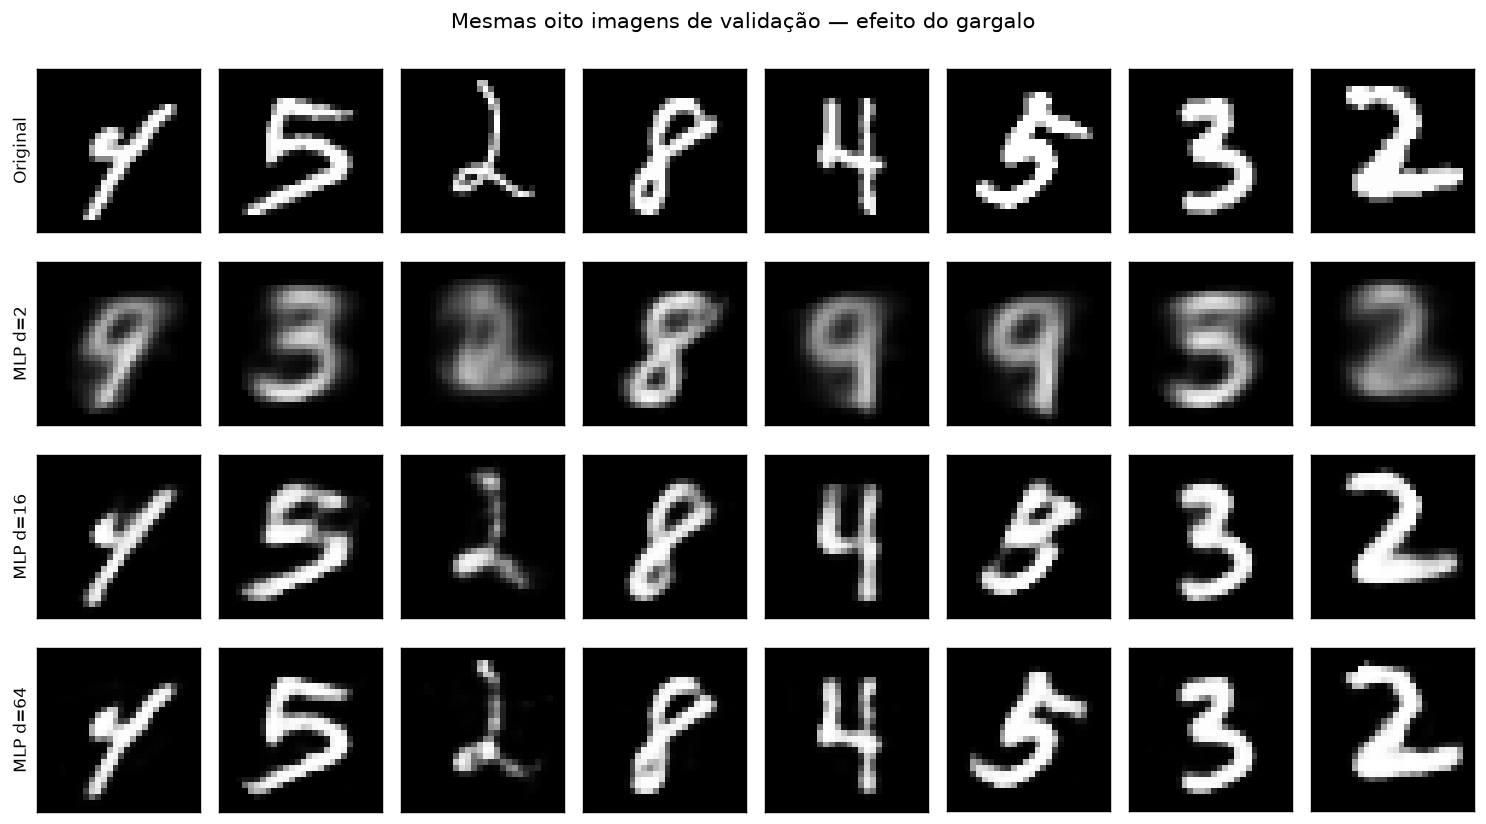

Dimensão latente,Melhor MSE validação
2,0.042836
16,0.011613
64,0.004007


In [16]:
def show_reconstructions(models, images, title):
    """Cada linha usa as MESMAS oito imagens, para permitir comparação visual."""
    images = images[:8].to(device)
    rows = [("Original", images.cpu())]
    for name, model in models.items():
        model.eval()
        with torch.no_grad():
            rows.append((name, model(images).cpu()))
    fig, axes = plt.subplots(len(rows), 8, figsize=(12, 1.7 * len(rows)))
    for row, (label, batch) in enumerate(rows):
        for col in range(8):
            axes[row, col].imshow(batch[col, 0], cmap="gray", vmin=0, vmax=1)
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
        axes[row, 0].set_ylabel(label, fontsize=10)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# Usa validação para explorar os gargalos; o teste fica para a parte 4.
val_images, val_labels = next(iter(val_loader))
show_reconstructions(
    {f"MLP d={d}": autoencoders[d] for d in [2, 16, 64]},
    val_images, "Mesmas oito imagens de validação — efeito do gargalo"
)
display(pd.DataFrame([
    {"Dimensão latente": d, "Melhor MSE validação": ae_experiments[f"MLP_{d}"]["best_loss"]}
    for d in [2, 16, 64]
]).round(6))

### 3.3 Interpolação
Escolhemos duas imagens de validação com rótulos diferentes. Decodificamos
`z(α) = (1−α)z_a + αz_b` para nove valores de α: dois extremos e
**sete pontos intermediários**. Os rótulos ajudam apenas a escolher e identificar
as imagens; não entram no treinamento do autoencoder.

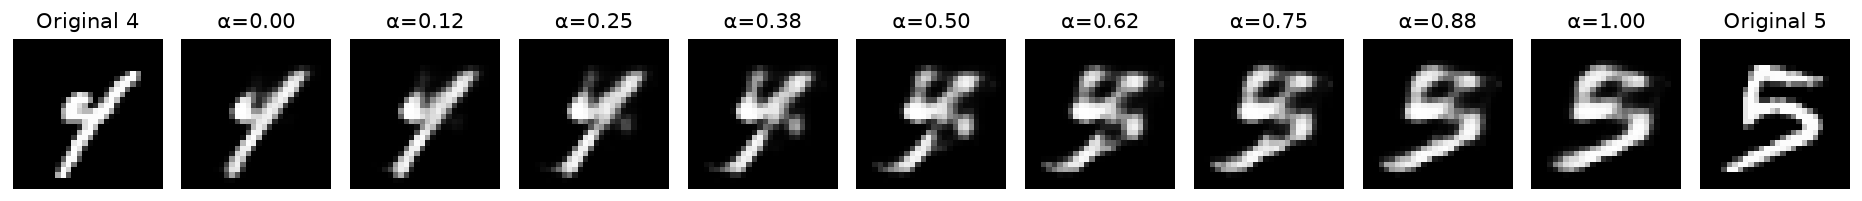

In [17]:
def interpolate(model, image_a, image_b, label_a, label_b, steps=9):
    model.eval()
    with torch.no_grad():
        a = model.encode(image_a.unsqueeze(0).to(device))
        b = model.encode(image_b.unsqueeze(0).to(device))
        alpha = torch.linspace(0, 1, steps, device=device).view(-1, 1)
        zs = (1 - alpha) * a + alpha * b  # Combinação linear dos dois códigos.
        outputs = model.decode(zs).cpu()
    fig, axes = plt.subplots(1, steps + 2, figsize=(15, 2))
    axes[0].imshow(image_a[0], cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"Original {label_a}")
    for i in range(steps):
        axes[i + 1].imshow(outputs[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[i + 1].set_title(f"α={i / (steps - 1):.2f}")
    axes[-1].imshow(image_b[0], cmap="gray", vmin=0, vmax=1)
    axes[-1].set_title(f"Original {label_b}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# O segundo índice tem um rótulo diferente do primeiro.
index_b = int(torch.where(val_labels != val_labels[0])[0][0])
interpolate(autoencoders[16], val_images[0], val_images[index_b],
            val_labels[0].item(), val_labels[index_b].item())

### 3.4 Amostras aleatórias do espaço latente
Sorteamos **12 vetores de N(0,I) para d=2 e outros 12 para d=16**.
Isso é diferente de interpolar entre duas imagens conhecidas.

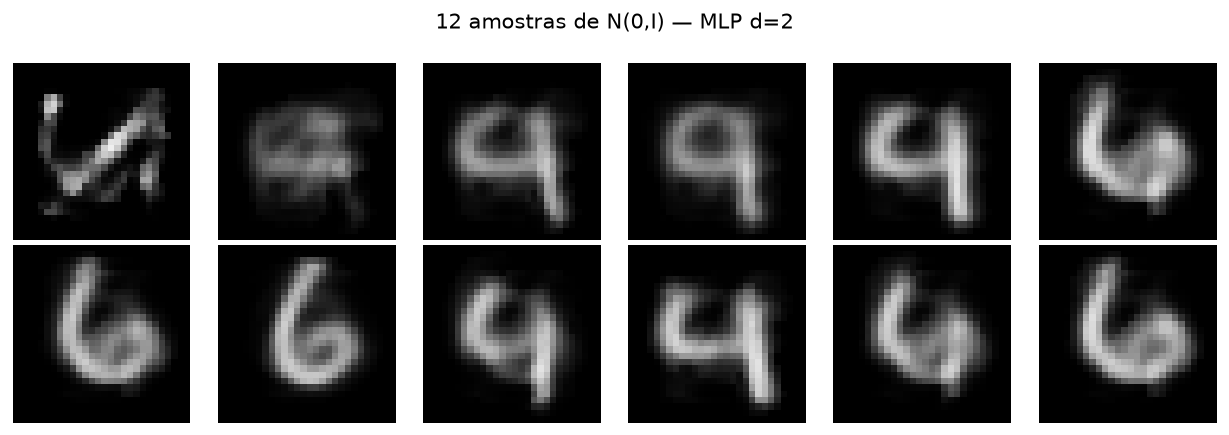

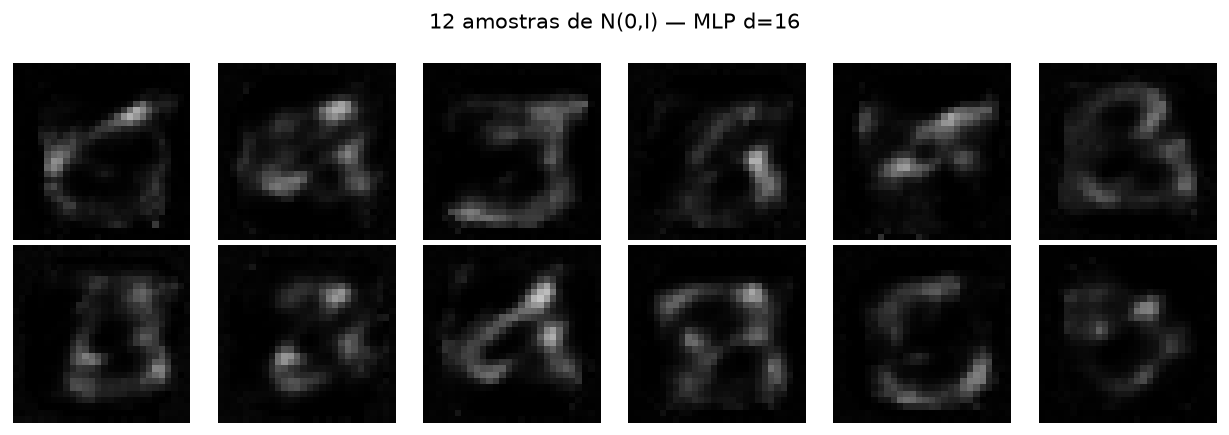

In [18]:
def show_random_decodes(model, latent_dim, n=12):
    model.eval()
    # Gerador local: permite repetir as amostras sem alterar o treinamento.
    generator = torch.Generator().manual_seed(SEED)
    zs = torch.randn(n, latent_dim, generator=generator).to(device)
    with torch.no_grad():
        decoded = model.decode(zs).cpu()
    fig, axes = plt.subplots(2, 6, figsize=(10, 3.5))
    for ax, image in zip(axes.flat, decoded):
        ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    fig.suptitle(f"12 amostras de N(0,I) — MLP d={latent_dim}")
    plt.tight_layout()
    plt.show()

show_random_decodes(autoencoders[2], 2)
show_random_decodes(autoencoders[16], 16)

### Respostas da parte 3
**1. Para que serve o gargalo?** Ele obriga a representar 784 pixels usando poucos
números. A rede precisa preservar informações úteis à reconstrução, em vez de
simplesmente copiar cada pixel por uma conexão independente.

**2. O que muda de 2 para 16 e 64?** A tabela de validação e a figura com as mesmas
imagens quantificam a mudança. Mais dimensões permitem reter detalhes, mas também
mudam a quantidade de parâmetros. O resultado observado, sem presumir uma ordem
obrigatória de desempenho, é discutido logo abaixo.

**3. O que acontece na interpolação?** O código percorre uma linha entre dois
vetores conhecidos. O decoder transforma esse caminho em mudanças nos traços.
Continuidade numérica não garante que cada imagem intermediária seja um dígito
legível. Os extremos são reconstruções; por isso podem diferir dos originais.

**4. Por que vetores aleatórios podem falhar?** O treinamento do AE comum não
obriga os códigos a seguirem N(0,I). Assim, amostras dessa distribuição podem
cair longe das regiões usadas no treino. O decoder pode produzir manchas,
traços incompletos ou imagens repetitivas. Uma boa reconstrução não garante
boa geração a partir de amostras independentes.

**5. AE versus classificador:** o classificador recebe uma imagem e tenta acertar
seu rótulo com entropia cruzada. O AE recebe uma imagem e tenta reproduzir seus
pixels com MSE. O primeiro aprende a distinguir classes; o segundo aprende uma
representação útil para reconstruir.

### Observações desta execução
- **MLP d=2:** menor MSE de validação **0.042836**, na época **30**, com **202,258** parâmetros.
- **MLP d=16:** menor MSE de validação **0.011613**, na época **30**, com **205,856** parâmetros.
- **MLP d=64:** menor MSE de validação **0.004007**, na época **30**, com **218,192** parâmetros.


**Reconstruções:** com d=2, o quinto exemplo, originalmente um 4, ficou parecido
com um 9, e o segundo exemplo, um 5, aproximou-se de um 3. Os contornos ficaram
borrados. Com d=16, a maioria dos formatos foi recuperada, mas o sexto exemplo
ainda perdeu detalhes e ficou parecido com um 8. Com d=64, esse 5 ficou mais
próximo do original, e os contornos ficaram mais definidos. Isso acompanha a
queda do MSE de validação, sem garantir melhora de todo pixel ou exemplo.

**Interpolação:** usamos um 4 e um 5 da validação. O traço inclinado do 4 foi
mudando gradualmente, enquanto apareceram os traços curvos do 5. Perto do centro
do caminho há formas ambíguas, misturando características dos dois. Os extremos
reconstruídos são parecidos com as entradas, mas não são cópias perfeitas.

**Vetores aleatórios:** em d=2 aparecem várias formas semelhantes a 4, 6 e 9,
com repetição e borramento. Em d=16, as imagens ficaram especialmente escuras,
com traços fracos e incompletos. Portanto, o modelo que reconstrói melhor não
necessariamente gera melhor quando recebe N(0,I). Diferentemente da interpolação,
esse sorteio não parte de códigos de imagens reais.


**Decisão de parada baseada na validação:** nas cinco últimas épocas, nenhum autoencoder melhorou o melhor MSE anterior em mais de 0,0005 (maior ganho: 0.000334). Essa é a tolerância prática adotada para encerrar o orçamento comum em 30 épocas após a extensão da etapa de 20. É um critério de retorno decrescente, não uma prova de convergência matemática.

## Parte 4 — Autoencoder convolucional e comparação
O MLP ignora a estrutura 2D ao achatar os pixels. A CNN usa filtros locais e
compartilha seus pesos entre posições. Aqui comparamos ambas em **d=16 e d=64**,
com os mesmos dados, Adam, taxa de aprendizado, semente e número de épocas.

### Avaliação final no teste
Os quatro modelos abaixo já tiveram seus checkpoints escolhidos pela validação.
Cada um é avaliado **uma vez** no conjunto de teste completo. A seleção dos
modelos não será alterada depois de observar esses resultados.

In [19]:
# Calcula o MSE de teste e os parâmetros dos quatro modelos finais.
test_mse = {}
rows = []
for dim in [16, 64]:
    for architecture in ["MLP", "CNN"]:
        name = f"{architecture}_{dim}"
        exp = ae_experiments[name]
        stats = run_epoch(exp["model"], test_loader, nn.MSELoss(),
                          classification=False)
        test_mse[name] = stats["loss"]
        rows.append({
            "Arquitetura": architecture, "Dimensão": dim,
            "Épocas": len(exp["history"]["val_loss"]),
            "Melhor época": exp["best_epoch"],
            "Parâmetros treináveis": count_parameters(exp["model"]),
            "Melhor MSE validação": exp["best_loss"],
            "MSE teste": stats["loss"],
        })
ae_table = pd.DataFrame(rows)
display(ae_table.round(6))

Arquitetura,Dimensão,Épocas,Melhor época,Parâmetros treináveis,Melhor MSE validação,MSE teste
MLP,16,30,30,205856,0.011613,0.011293
CNN,16,30,30,65025,0.008472,0.008340
MLP,64,30,30,218192,0.004007,0.003870
CNN,64,30,29,215601,0.002138,0.002082


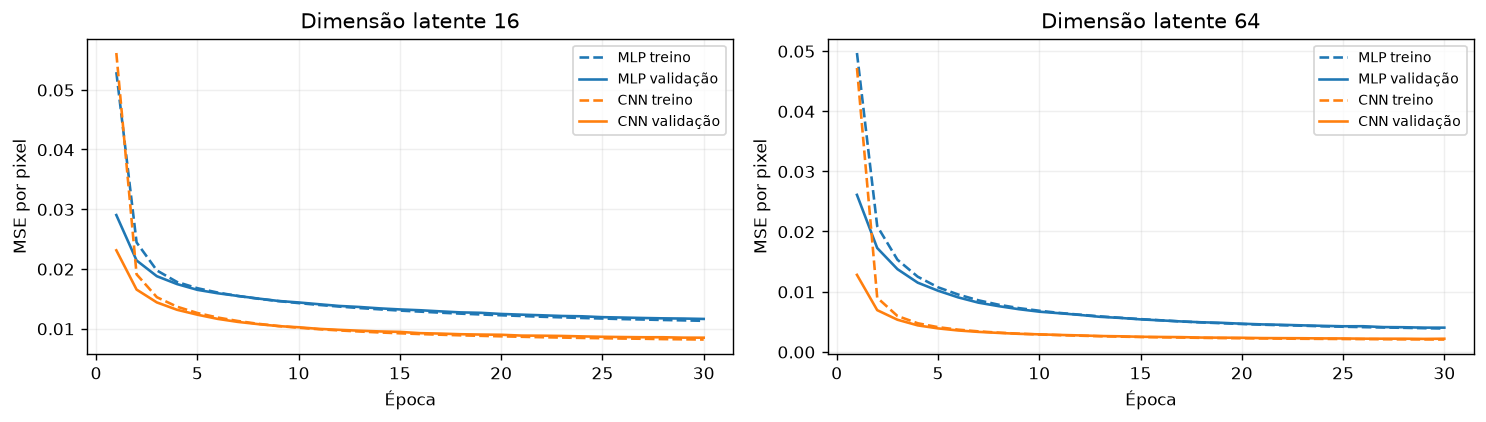

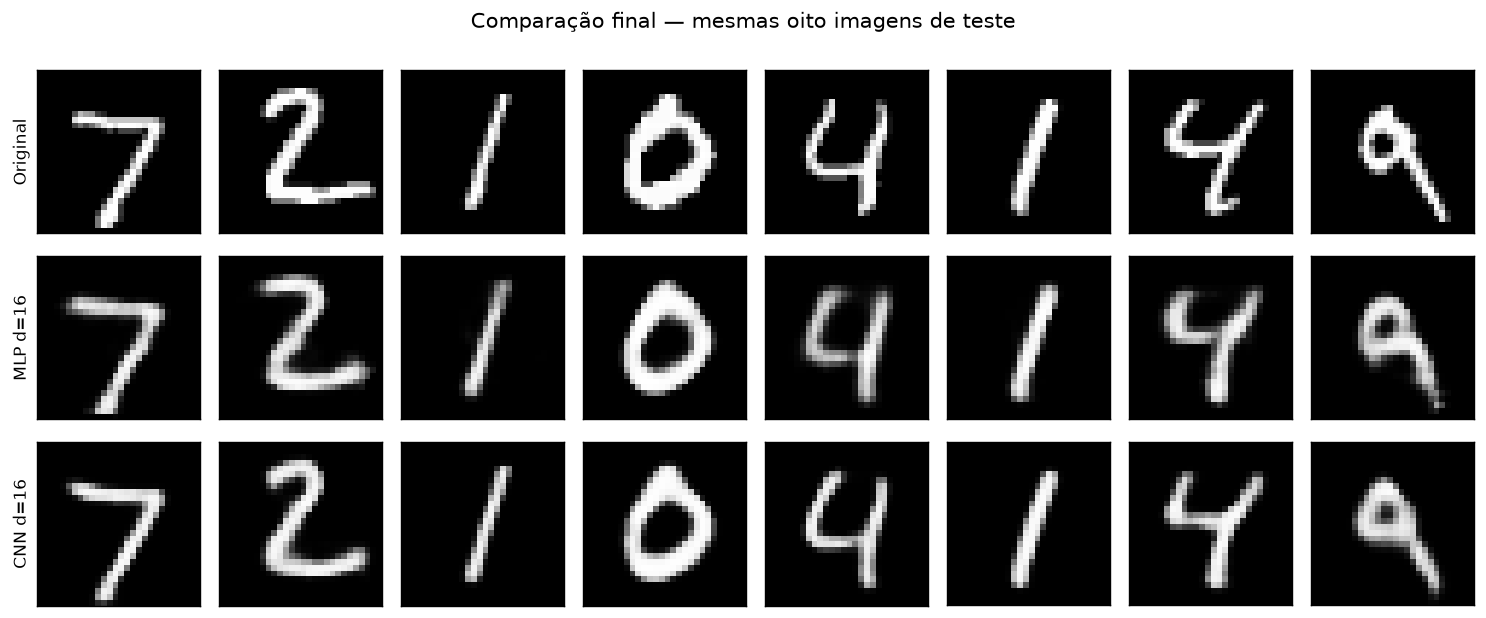

In [20]:
# Uma linha por dimensão; linhas contínuas são validação, tracejadas são treino.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, dim in zip(axes, [16, 64]):
    for architecture, color in [("MLP", "tab:blue"), ("CNN", "tab:orange")]:
        h = ae_experiments[f"{architecture}_{dim}"]["history"]
        epochs = range(1, len(h["val_loss"]) + 1)
        ax.plot(epochs, h["train_loss"], "--", color=color,
                label=architecture + " treino")
        ax.plot(epochs, h["val_loss"], color=color,
                label=architecture + " validação")
    ax.set_title(f"Dimensão latente {dim}")
    ax.set_xlabel("Época")
    ax.set_ylabel("MSE por pixel")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Os primeiros oito exemplos do teste são compartilhados pelas duas redes.
test_images, test_labels = next(iter(test_loader))
show_reconstructions(
    {"MLP d=16": autoencoders[16], "CNN d=16": conv_autoencoders[16]},
    test_images, "Comparação final — mesmas oito imagens de teste"
)

### Como `ConvTranspose2d` recupera 28×28?
Ela aplica filtros aprendidos para aumentar a resolução espacial.
**Não é a inversa matemática** de uma convolução: a redução anterior pode perder
informação, e os filtros do decoder são aprendidos separadamente.

Para cada eixo:

`saída = (entrada − 1) × stride − 2 × padding + dilation × (kernel − 1) + output_padding + 1`

Com `stride=2`, `padding=1`, `kernel=4`, `dilation=1` e `output_padding=0`:

- `7 → (7−1)×2 − 2 + 3 + 1 = 14`
- `14 → (14−1)×2 − 2 + 3 + 1 = 28`

No encoder, convoluções com kernel 3, stride 2 e padding 1 reduzem
`28 → 14 → 7`, usando o arredondamento para baixo da fórmula da convolução.
Os testes de formato confirmam a saída `(N,1,28,28)`.

### Análise escrita
Os cinco autoencoders treinaram por 30 épocas, com Adam, taxa 0,001, lote 128 e
a mesma divisão dos dados. Após cinco épocas de teste inicial, continuei até 20;
como a validação ainda melhorava, estendi todos até 30. Nas últimas cinco épocas,
o maior ganho absoluto de MSE de validação foi 0,000334, abaixo da tolerância
prática de 0,0005. Esse retorno decrescente justificou encerrar o orçamento
comum, sem afirmar convergência matemática. Selecionei os melhores pesos pela
validação e somente depois avaliei o teste.

Com dimensão 16, o MSE de teste foi 0.011293 no MLP e
0.008340 na CNN; com dimensão 64, foi 0.003870 e
0.002082, respectivamente. A CNN apresentou menor erro nas duas
comparações. Nas imagens, o topo curvo do segundo exemplo, um 2, foi mais bem
preservado pela CNN; o MLP produziu um traço mais horizontal. As curvas também
mostram perdas de validação menores para a CNN.

Isso não prova superioridade geral. Em dimensão 16, a CNN tem 65.025 parâmetros
e o MLP 205.856; portanto, a capacidade não foi igualada. Épocas iguais tampouco
significam tempo ou custo computacional iguais. Uma única semente e um único
dataset limitam a conclusão.

ConvTranspose2d aprende a aumentar a resolução e não é a inversa matemática do
encoder. Com kernel 4, stride 2 e padding 1, os tamanhos são
(7−1)×2−2+4=14 e (14−1)×2−2+4=28.

## Referências
- Notebook **Assignment 1 — From Classification to Autoencoders**, fornecido pela disciplina.
- **1_Deep Learning.pdf**, especialmente as páginas 34–36 (CNN),
  40–46 (Dropout e avaliação) e 47–52 (BatchNorm).
- **0_CNN_lecture_2025.pdf**, para os conceitos de convolução e pooling.
- **VAE: A Gentle Introduction and PyTorch Implementation**, seções iniciais
  sobre reconstrução, gargalo e limites da amostragem em autoencoders comuns.
- Materiais de slides e código fornecidos pela disciplina,
  incluindo o exemplo `04_cnn_mnist.py`, conferido na preparação.

A localização do Dropout segue o enunciado específico desta atividade.
Não utilizamos modelos pré-treinados. O VAE opcional não foi implementado.